In [ ]:
!pip install rasterio

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Importing required libraries
import os
import numpy as np
import cv2
import pandas as pd
import rasterio as rio
from matplotlib import pyplot as plt
import seaborn as sns
import joblib
import json
import geopandas as gpd
from sklearn.preprocessing import MinMaxScaler ,StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
# Read the shapefile
df = gpd.read_file("/content/drive/MyDrive/Flood_Susceptibility/New_Inventory/flood_invent_400.shp")
df.head()


,grid_code,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,TPI,NDVI,Rainfall,geometry
0,0,21.0,7.210669,1000.0,0.567845,5.603608,1.0,4.0,5.040757,34.478920,0.333333,2.405406,0.272727,2458.048096,POINT (648293.817 1116408.852)
1,0,14.0,5.139694,1000.0,0.444897,10.679511,1.0,4.0,7.578450,-20.343735,-0.444444,-1.729730,0.211433,2446.077881,POINT (648401.005 1117212.764)
2,0,32.0,4.380487,1000.0,0.676938,5.948130,1.0,4.0,4.632522,1.221863,0.333333,2.324324,0.578451,2490.737305,POINT (649472.887 1114693.841)
3,0,29.0,3.945476,1000.0,0.793863,7.326543,3.0,4.0,6.156691,48.258034,0.111111,1.486486,0.776360,2553.509277,POINT (650330.393 1113193.206)
4,0,12.0,1.909152,1000.0,0.743280,7.876605,5.0,4.0,4.476785,-50.000000,-0.555556,-1.081081,0.511879,2492.831543,POINT (651080.711 1114318.682)


In [ ]:
import pandas as pd
import numpy as np

# Define the valid ranges for each feature based on the images provided
valid_ranges = {
    'Relief': (3, 717),
    'Slope': (0, 58.9553),
    'Dis_River': (100, 1000),
    'Drai_Density': (0.0025849712, 4.8236695),
    'TWI': (3.3658473491669, 30.28600692749),
    'LULC': (1, 7),
    'Geomorphology': (1, 18),
    'SPI': (1.6694390773773, 15.068050384521),
    'Conv_Index': (-100, 100),
    'Curvature': (-10.111110687256, 7.4444446563721),
    'TPI': (-38.324325561523, 35.216217041016),
    'NDVI': (-0.4285714328289, 0.89060252904892),
    'Rainfall': (1849.0091552734, 3915.3872070312)  # Based on the new image provided
}

# Create a mask to identify points with values within valid ranges
mask = pd.Series(True, index=df.index)

# Check each column against its valid range
for column, (min_val, max_val) in valid_ranges.items():
    if column in df.columns:
        # Create a column-specific mask that's True for values within the valid range
        # Also consider NaN values as invalid
        column_mask = (
            (df[column] >= min_val) &
            (df[column] <= max_val) &
            (~df[column].isna()) &
            # Filter out extreme floating point values that might represent NoData
            (~np.isinf(df[column])) &
            (df[column] != -3.402823e+38) &
            (df[column] != 3.400000e+38) &
            (df[column] != -99999.0)
        )

        # Update the overall mask by performing an AND operation
        mask = mask & column_mask

# Apply the mask to filter the points
df02 = df[mask].copy()
df02.drop('TPI', axis=1, inplace=True)
# Check how many points were filtered out
print(f"Original number of points: {len(df)}")
print(f"Number of points after filtering: {len(df02)}")
print(f"Number of points removed: {len(df) - len(df02)}")

# Check the filtered GeoDataFrame
df02.head()

# Optional: Save the filtered points to a new shapefile
# filtered_points.to_file("filtered_points.shp")

Original number of points: 523
Number of points after filtering: 472
Number of points removed: 51


,grid_code,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,NDVI,Rainfall,geometry
0,0,21.0,7.210669,1000.0,0.567845,5.603608,1.0,4.0,5.040757,34.478920,0.333333,0.272727,2458.048096,POINT (648293.817 1116408.852)
1,0,14.0,5.139694,1000.0,0.444897,10.679511,1.0,4.0,7.578450,-20.343735,-0.444444,0.211433,2446.077881,POINT (648401.005 1117212.764)
2,0,32.0,4.380487,1000.0,0.676938,5.948130,1.0,4.0,4.632522,1.221863,0.333333,0.578451,2490.737305,POINT (649472.887 1114693.841)
3,0,29.0,3.945476,1000.0,0.793863,7.326543,3.0,4.0,6.156691,48.258034,0.111111,0.776360,2553.509277,POINT (650330.393 1113193.206)
4,0,12.0,1.909152,1000.0,0.743280,7.876605,5.0,4.0,4.476785,-50.000000,-0.555556,0.511879,2492.831543,POINT (651080.711 1114318.682)


In [ ]:
#check that there is no no data values in the dataset
print(df02.isnull().sum())

grid_code     0
Relief        0
Slope         0
Dis_River     0
Drai_Densi    0
TWI           0
LULC          0
Geomorphol    0
SPI           0
Conv_Index    0
Curvature     0
NDVI          0
Rainfall      0
geometry      0
dtype: int64


grid_code
1    247
0    225
Name: count, dtype: int64


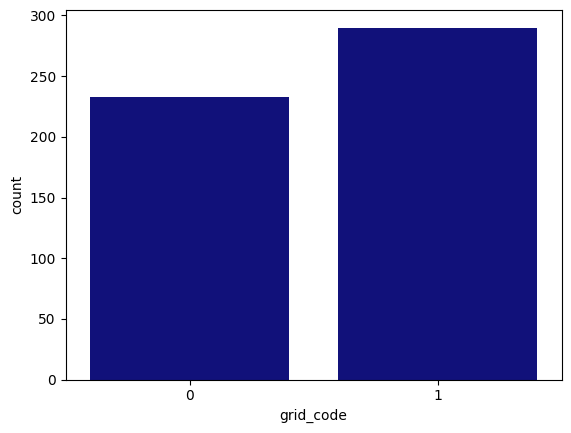

In [ ]:
# Understand the data
# Here we can see that we have a balanced dataset (equal number of flooded and non flooeded locations
sns.countplot(x="grid_code", data=df,color = 'darkblue') # 0 - Notflooded   B - Flooded

# print the number of 1 and 0 (grid_code)
print(df02['grid_code'].value_counts())

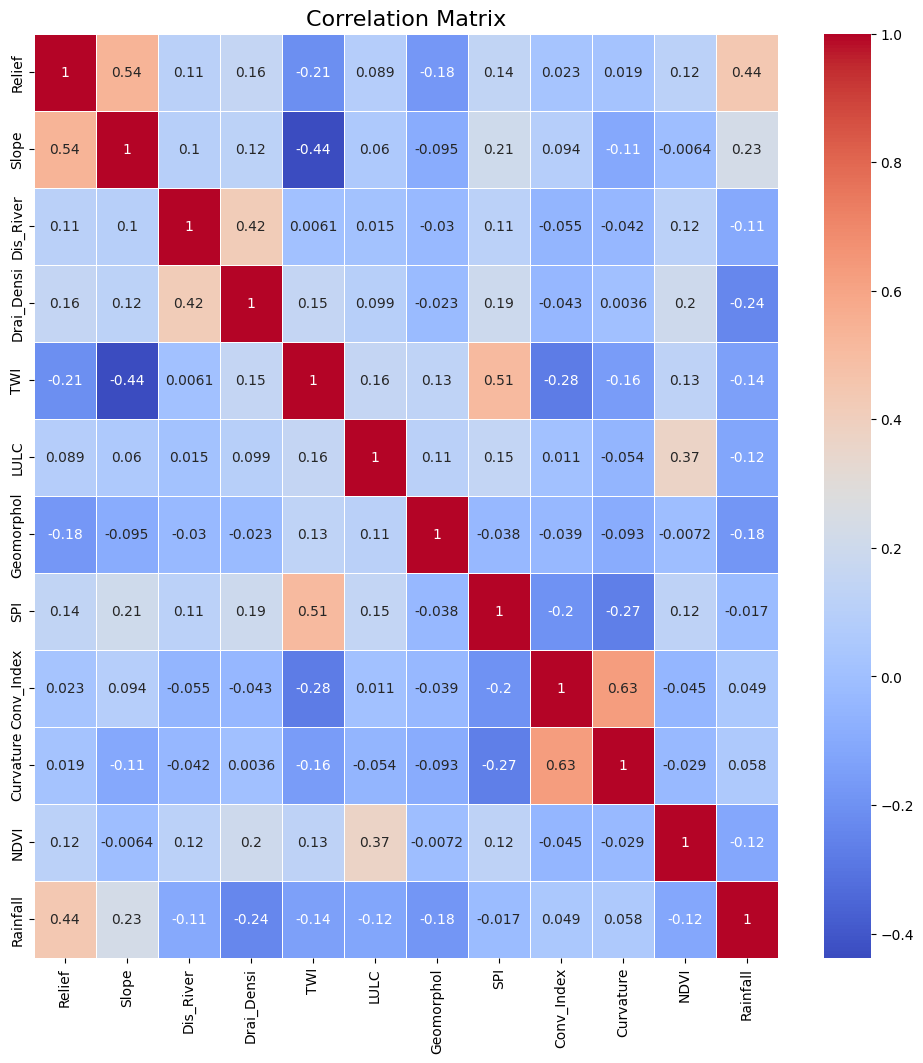

In [ ]:
# Select only numeric columns for correlation matrix
numeric_df = df02.select_dtypes(include=[np.number])

# To remove the column 'GRIDCODE'
numeric_df = numeric_df.drop('grid_code', axis=1)

# Compute the correlation matrix
corrMatrix = numeric_df.corr()

# Plot the heatmap
fig, ax = plt.subplots(figsize=(12, 12))  # Adjust figsize as needed
sns.heatmap(corrMatrix, annot=True, linewidths=0.5, ax=ax, cmap='coolwarm')

plt.title("Correlation Matrix", fontsize=16)
plt.show()


In [ ]:
# Define the dependent variable that needs to be predicted (labels)
Y = df02["grid_code"].values

# Define the independent variables. Let's also drop geometry and label.
X = df02.drop(labels = ["grid_code", "geometry"], axis=1)
features_list = list(X.columns)  #List features so we can rank their importance later
features_list

['Relief',
 'Slope',
 'Dis_River',
 'Drai_Densi',
 'TWI',
 'LULC',
 'Geomorphol',
 'SPI',
 'Conv_Index',
 'Curvature',
 'NDVI',
 'Rainfall']

In [ ]:
# Train-test split
# Split data into train (60 %), validate (20 %) and test (20%) to verify accuracy after fitting the model.
# training data is used to train the model
# validation data is used for hyperparameter tuning
# testing data is used to test the model

X_train_val, X_test, y_train_val, y_test = train_test_split(X, Y, test_size=0.2,shuffle=True, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25,shuffle=True, random_state=42)
X_train.shape, X_val.shape, X_test.shape

((282, 12), (95, 12), (95, 12))

In [ ]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler ONLY on training data
scaler.fit(X_train)

# Transform each dataset with the scaler that was fit on training data
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# Check the normalized training data
X_train_scaled.head()

,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,NDVI,Rainfall
0,-0.159577,0.558556,0.632481,-0.262056,-0.802402,-1.267635,-0.342830,0.250266,-0.602432,-0.160262,-0.504509,0.676214
1,-0.277033,-0.339088,-1.121876,0.400162,0.807390,-1.267635,5.949829,-0.103661,-1.087382,-0.722843,-0.720646,0.592175
2,-0.071484,1.099861,0.632481,-0.184957,-1.204075,-1.267635,-0.342830,-0.165329,-0.032682,-0.722843,-2.946446,1.045879
3,-0.277033,-0.144844,0.632481,-0.260088,-0.646097,-1.267635,0.229230,-0.543603,0.521169,0.214791,0.691222,1.003294
4,-0.247669,-0.200622,-1.121876,0.190209,0.078385,0.346239,-0.342830,-0.869833,1.064242,0.589845,-0.355356,-2.069434


In [ ]:
# Define folder structure
base_dir = "/content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project"
data_dir = os.path.join(base_dir, "data")

# Create directories if they don't exist
os.makedirs(data_dir, exist_ok=True)

# Function to save data splits as CSV
def save_data_splits(X_train, X_val, X_test,
                    y_train, y_val, y_test,
                    X_train_scaled, X_val_scaled, X_test_scaled,
                    features_list, scaler):
  # Save the dataframes as CSV
    X_train.to_csv(os.path.join(data_dir, 'X_train.csv'), index=False)
    X_val.to_csv(os.path.join(data_dir, 'X_val.csv'), index=False)
    X_test.to_csv(os.path.join(data_dir, 'X_test.csv'), index=False)

    # Save target variables
    pd.DataFrame(y_train, columns=['target']).to_csv(os.path.join(data_dir, 'y_train.csv'), index=False)
    pd.DataFrame(y_val, columns=['target']).to_csv(os.path.join(data_dir, 'y_val.csv'), index=False)
    pd.DataFrame(y_test, columns=['target']).to_csv(os.path.join(data_dir, 'y_test.csv'), index=False)

    # Save scaled data
    X_train_scaled.to_csv(os.path.join(data_dir, 'X_train_scaled.csv'), index=False)
    X_val_scaled.to_csv(os.path.join(data_dir, 'X_val_scaled.csv'), index=False)
    X_test_scaled.to_csv(os.path.join(data_dir, 'X_test_scaled.csv'), index=False)

    # Save features list
    pd.DataFrame(features_list, columns=['features']).to_csv(os.path.join(data_dir, 'features_list.csv'), index=False)

    # Save scaler separately using joblib
    joblib.dump(scaler, os.path.join(data_dir, 'scaler.joblib'))

    print(f"Data splits saved successfully to {data_dir}!")
    print(f"Training set: {X_train.shape[0]} samples")
    print(f"Validation set: {X_val.shape[0]} samples")
    print(f"Test set: {X_test.shape[0]} samples")



In [ ]:
# Save the splits
save_data_splits(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    X_train_scaled, X_val_scaled, X_test_scaled,
    features_list, scaler
)

Data splits saved successfully to /content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project/data!
Training set: 282 samples
Validation set: 95 samples
Test set: 95 samples


In [ ]:
# Function to load data splits from CSV
def load_data_splits():

    # First check if files exist
    required_files = ['X_train.csv', 'X_val.csv', 'X_test.csv',
                     'y_train.csv', 'y_val.csv', 'y_test.csv',
                     'X_train_scaled.csv', 'X_val_scaled.csv', 'X_test_scaled.csv',
                     'features_list.csv', 'scaler.joblib']

    files_exist = all(os.path.exists(os.path.join(data_dir, file)) for file in required_files)

    if not files_exist:
        print("Error: Data splits not found. Please run save_data_splits() first.")
        return None

    # Load the dataframes
    X_train = pd.read_csv(os.path.join(data_dir, 'X_train.csv'))
    X_val = pd.read_csv(os.path.join(data_dir, 'X_val.csv'))
    X_test = pd.read_csv(os.path.join(data_dir, 'X_test.csv'))

    # Load target variables
    y_train = pd.read_csv(os.path.join(data_dir, 'y_train.csv'))['target'].values
    y_val = pd.read_csv(os.path.join(data_dir, 'y_val.csv'))['target'].values
    y_test = pd.read_csv(os.path.join(data_dir, 'y_test.csv'))['target'].values

    # Load scaled data
    X_train_scaled = pd.read_csv(os.path.join(data_dir, 'X_train_scaled.csv'))
    X_val_scaled = pd.read_csv(os.path.join(data_dir, 'X_val_scaled.csv'))
    X_test_scaled = pd.read_csv(os.path.join(data_dir, 'X_test_scaled.csv'))

    # Load features list
    features_list = pd.read_csv(os.path.join(data_dir, 'features_list.csv'))['features'].tolist()

    # Load scaler
    scaler = joblib.load(os.path.join(data_dir, 'scaler.joblib'))

    # Print summary of loaded data
    print(f"Data splits loaded successfully from {data_dir}!")
    print(f"Training set: {X_train.shape[0]} samples")
    print(f"Validation set: {X_val.shape[0]} samples")
    print(f"Test set: {X_test.shape[0]} samples")

    # Return all data as a dictionary
    return {
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test,
        'y_train': y_train,
        'y_val': y_val,
        'y_test': y_test,
        'X_train_scaled': X_train_scaled,
        'X_val_scaled': X_val_scaled,
        'X_test_scaled': X_test_scaled,
        'features_list': features_list,
        'scaler': scaler
    }

In [ ]:
# Load saved splits before training any model
data = load_data_splits()

if data is not None:
    # Extract the data components
    X_train = data['X_train']
    X_val = data['X_val']
    X_test = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']
    X_train_scaled = data['X_train_scaled']
    X_val_scaled = data['X_val_scaled']
    X_test_scaled = data['X_test_scaled']
    features_list = data['features_list']
    scaler = data['scaler']

Data splits loaded successfully from /content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project/data!
Training set: 282 samples
Validation set: 95 samples
Test set: 95 samples


In [ ]:
X_train_scaled.head()

,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,NDVI,Rainfall
0,-0.159577,0.558556,0.632481,-0.262056,-0.802402,-1.267635,-0.342830,0.250266,-0.602432,-0.160262,-0.504509,0.676214
1,-0.277033,-0.339088,-1.121876,0.400162,0.807390,-1.267635,5.949829,-0.103661,-1.087382,-0.722843,-0.720646,0.592175
2,-0.071484,1.099861,0.632481,-0.184957,-1.204075,-1.267635,-0.342830,-0.165329,-0.032682,-0.722843,-2.946446,1.045879
3,-0.277033,-0.144844,0.632481,-0.260088,-0.646097,-1.267635,0.229230,-0.543603,0.521169,0.214791,0.691222,1.003294
4,-0.247669,-0.200622,-1.121876,0.190209,0.078385,0.346239,-0.342830,-0.869833,1.064242,0.589845,-0.355356,-2.069434
